# News source datapost: article plots

Makes the two charts in the social media news datapost, styled like the religion datapost ([Which religions are the least tolerant of campus speakers?](https://expression.fire.org/p/which-religions-are-the-least-tolerant)), plus the sample-size numbers quoted in the text.

Data: `cfsrALL_2027_2026_only.csv`, the 2026 rows of the CFSR megafile (`cfsrALL_2027.csv`), with variables described in `cfsrALL_2027_codebook.csv`.

Notes:
- **Quitters excluded.** The news question is in the last survey block. Respondents who quit before reaching it have 0 for every news source, so they would show up as "None." They're identified here as *no source selected and no answers to the rest of that block* (`numclosefriends`, `attendreligserv`, `armedforces`, `veteran`). Removing them leaves only 75 students who finished the survey and picked no source, so the "None" point is dropped (`SHOW_NONE = False`).
- **Average markers.** Red X's for all men and all women (every student who saw the news question). Chart 2 also marks the averages for one-source men and women. All are student-level means, so students with several sources aren't counted more than once.
- **Styling.** Men = circles, women = squares; legend under the plot; n's are printed under each chart. TV/radio site is cyan rather than red so it can't be mistaken for the red average markers.

Outputs (in `charts/`):
- `news_source_gender_tolerance_diamond_2026.png` (+ `.csv` point readout)
- `news_source_gender_tolerance_diamond_single_source_only_2026.png` (+ `.csv`)
- `social_media_news_share_by_gender_2026.csv` (the percentages in the text)


In [1]:
from pathlib import Path
from typing import Callable, Optional

import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import to_rgb
from matplotlib.lines import Line2D
from matplotlib.patches import Circle, FancyArrowPatch, Polygon
from matplotlib.path import Path as MplPath
from matplotlib.text import Text

# =========================
# Config
# =========================
DATA_PATH = Path("cfsrALL_2027_2026_only.csv")
CODEBOOK_PATH = Path("cfsrALL_2027_codebook.csv")
OUT_DIR = Path("charts")
OUT_DIR.mkdir(parents=True, exist_ok=True)

SHOW_NONE = False                 # the "None" group is 75 people once quitters are removed
SINGLE_SOURCE_DROP: list[str] = []  # e.g. ["news_radio", "news_radiotvweb", ...] to leave noisy single-source groups off chart 2

RIGHT_TRIAD = ["spk_abortion", "spk_trans", "spk_blm"]         # abortion illegal, trans mental disorder, BLM hate group
LEFT_TRIAD = ["spk_cathped", "spk_policekkk", "spk_kidtrans"]   # Catholic church, police/KKK, child transition
SPK_ALL = RIGHT_TRIAD + LEFT_TRIAD
NEWS_SOURCE_COLS = [
    "news_socmedia", "news_tv", "news_radio", "news_radiotvweb", "news_podcast",
    "news_newspaperprint", "news_newspaperonline", "news_studentprint", "news_studentonline",
]
# Asked in the same final block as the news question. numclosefriends is blank when unanswered;
# the others use 99 = Missing (98 = Not in survey).
LAST_BLOCK_NUMERIC = "numclosefriends"
LAST_BLOCK_CODED = ["attendreligserv", "armedforces", "veteran"]

NEWS_SOURCE_LABELS = {
    "news_socmedia": "Social media",
    "news_tv": "TV",
    "news_radio": "Radio",
    "news_radiotvweb": "TV/radio site",
    "news_podcast": "Podcast",
    "news_newspaperprint": "Print news",
    "news_newspaperonline": "Online news",
    "news_studentprint": "Student print",
    "news_studentonline": "Student online",
    "none": "None",
}
NEWS_SOURCE_COLORS = {
    "news_socmedia": "#1f77b4",
    "news_tv": "#ff7f0e",
    "news_radio": "#2ca02c",
    "news_radiotvweb": "#17becf",  # was red (#d62728); changed so it can't be confused with the red average markers
    "news_podcast": "#9467bd",
    "news_newspaperprint": "#8c564b",
    "news_newspaperonline": "#e377c2",
    "news_studentprint": "#7f7f7f",
    "news_studentonline": "#bcbd22",
    "none": "#111827",
}
GENDER_LABELS = {1: "Men", 2: "Women"}
GENDER_MARKERS = {1: "o", 2: "s"}

FIG_W, FIG_H = 8.8 * 1.3, 8.6 * 1.3
POINT_SIZE = 130
AVG_MARKER_SIZE = 380
LABEL_FONTSIZE = 12.0
BUFFER_PP_MIN = 1.5
BUFFER_FRAC = 0.06
SUPTITLE_Y = 0.925
TITLE_PAD = 6
CREDIT_TEXT = (
    "Chart: Chapin Lenthall-Cleary\n"
    "Source: FIRE's 2027 College Free\n"
    "Speech Rankings Survey (2026 data)"
)
CREDIT_X, CREDIT_Y = 0.875, 0.125
CREDIT_COLOR = "#4b5563"
LEGEND_ANCHOR = (0.110, 0.080)

COMPASS_W = 0.40
COMPASS_H = 0.30
COMPASS_PAD = 0.006
COMPASS_SHIFT_RIGHT = 0.10

P0 = np.array([50.0, 0.0])
VL = np.array([-50.0, 50.0])
VR = np.array([50.0, 50.0])


# =========================
# Diamond helpers (same as the religion datapost)
# =========================
def to_diamond_xy(left_vals, right_vals):
    left_vals = np.asarray(left_vals, dtype=float)
    right_vals = np.asarray(right_vals, dtype=float)
    xy = P0 + (left_vals / 100.0)[..., None] * VL + (right_vals / 100.0)[..., None] * VR
    return xy[..., 0], xy[..., 1]


def compute_zoom_range(left_vals, right_vals) -> tuple[float, float]:
    left = pd.to_numeric(pd.Series(left_vals), errors="coerce").dropna()
    right = pd.to_numeric(pd.Series(right_vals), errors="coerce").dropna()
    if left.empty or right.empty:
        return 0.0, 100.0
    minv = float(min(left.min(), right.min()))
    maxv = float(max(left.max(), right.max()))
    span = max(1e-6, maxv - minv)
    buffer = max(BUFFER_PP_MIN, BUFFER_FRAC * span)
    lo = max(0.0, minv - buffer)
    hi = min(100.0, maxv + buffer)
    if hi - lo < 5:
        mid = (hi + lo) / 2.0
        lo = max(0.0, mid - 2.5)
        hi = min(100.0, mid + 2.5)
    return lo, hi


def normalize_to_zoom(vals, lo: float, hi: float):
    return np.clip((np.asarray(vals, dtype=float) - lo) / max(1e-9, hi - lo) * 100.0, 0, 100)


def zoom_axis_ticks(lo: float, hi: float):
    span = max(1e-9, hi - lo)
    label_step = 5.0 if span <= 35 else 10.0 if span <= 70 else 20.0
    tick_step = 5.0  # tick marks only at 5% intervals
    grid_step = 5.0

    first = np.ceil(lo / tick_step) * tick_step
    last = np.floor(hi / tick_step) * tick_step
    tick_values = np.arange(first, last + tick_step * 0.25, tick_step)
    tick_values = tick_values[(tick_values >= lo - 1e-9) & (tick_values <= hi + 1e-9)]
    if len(tick_values) < 2:
        tick_values = np.linspace(lo, hi, 5)

    raw_positions = (tick_values - lo) / span * 100.0
    snapped_positions = np.clip(np.round(raw_positions / grid_step) * grid_step, 0.0, 100.0)

    tick_positions = []
    labels_by_position: dict[float, str] = {}
    for pos, val in zip(snapped_positions, tick_values):
        pos = float(round(pos, 6))
        nearest = round(val / label_step) * label_step
        label = f"{int(round(nearest))}%" if abs(val - nearest) <= 1e-6 else ""
        if pos not in labels_by_position:
            tick_positions.append(pos)
            labels_by_position[pos] = label
        elif label and not labels_by_position[pos]:
            labels_by_position[pos] = label

    def tick_label_func(tick: float) -> str:
        return labels_by_position.get(float(round(tick, 6)), "")

    return tick_positions, tick_label_func


def add_2d_gradient_bg(ax, diamond_outline, *, nx=900, ny=900):
    x = np.linspace(0.0, 1.0, nx)
    y = np.linspace(0.0, 1.0, ny)
    X, Y = np.meshgrid(x, y)
    c_left = np.array(to_rgb("#93c5fd"))
    c_mid = np.array(to_rgb("#e5e7eb"))
    c_right = np.array(to_rgb("#fca5a5"))
    H = np.zeros((ny, nx, 3), dtype=float)
    u_left = np.clip(2 * X, 0, 1)
    u_right = np.clip(2 * (X - 0.5), 0, 1)
    for ch in range(3):
        H[..., ch] = np.where(
            X <= 0.5,
            (1 - u_left) * c_left[ch] + u_left * c_mid[ch],
            (1 - u_right) * c_mid[ch] + u_right * c_right[ch],
        )
    white = np.array(to_rgb("#ffffff"))
    gray = np.array(to_rgb("#e5e7eb"))
    t = np.clip(Y / 0.80, 0, 1)
    V = (1 - t)[..., None] * gray + t[..., None] * white
    bell = 1.0 - np.abs(2 * t - 1.0)
    alpha = 0.65 * bell
    img = (1 - alpha)[..., None] * V + alpha[..., None] * H
    shade_strength = np.clip((0.5 - Y) / 0.5, 0.0, 1.0)
    img *= 1.0 - 0.35 * shade_strength[..., None]
    img = np.clip(img, 0.0, 1.0)
    img[Y >= 0.85] = white
    im = ax.imshow(img, origin="lower", extent=[0, 100, 0, 100], interpolation="bilinear", zorder=-10)
    im.set_clip_path(diamond_outline)


def add_compass(ax, *, width=COMPASS_W, height=COMPASS_H, pad=COMPASS_PAD, shift_right=COMPASS_SHIFT_RIGHT):
    cx = 1 - pad - width / 2 + shift_right
    cy = 1 - pad - height / 2
    hx, hy = width / 2.0, height / 2.0
    m = min(width, height) * 0.06
    color = "#374151"

    def r_max(theta):
        ct, st = abs(np.cos(theta)), abs(np.sin(theta))
        return min((hx - m) / max(ct, 1e-9), (hy - m) / max(st, 1e-9))

    for angle_deg, label in [(90, "More tolerant"), (180, "Left-biased"), (0, "Right-biased"), (270, "Less tolerant")]:
        th = np.deg2rad(angle_deg)
        rmax = r_max(th)
        arr = FancyArrowPatch(
            (cx, cy),
            (cx + rmax * 0.62 * np.cos(th), cy + rmax * 0.62 * np.sin(th)),
            transform=ax.transAxes,
            arrowstyle="-|>",
            mutation_scale=13,
            linewidth=1.4,
            color=color,
            zorder=21,
        )
        arr.set_clip_on(False)
        ax.add_patch(arr)
        y_offset = 0.018 if label in {"Left-biased", "Right-biased"} else 0.0
        txt = ax.text(
            cx + rmax * 0.88 * np.cos(th),
            cy + rmax * 0.88 * np.sin(th) + y_offset,
            label,
            transform=ax.transAxes,
            ha="center",
            va="center",
            fontsize=12.5,
            color=color,
            zorder=22,
        )
        txt.set_clip_on(False)
    center = Circle((cx, cy), radius=min(width, height) * 0.012, transform=ax.transAxes, color=color, zorder=22)
    center.set_clip_on(False)
    ax.add_patch(center)


def draw_edge_axis(
    ax,
    p0,
    p1,
    *,
    label,
    tick_vals=range(0, 101, 10),
    tick_len=3.2,
    label_pad=11.0,
    tick_label_pad=2.0,
    label_fontsize=15,
    tick_fontsize=12,
    color="#111827",
    increasing_from="start",
    tick_label_func: Optional[Callable[[float], str]] = None,
):
    p0 = np.asarray(p0, float)
    p1 = np.asarray(p1, float)
    v = p1 - p0
    length = float(np.hypot(v[0], v[1]))
    u = v / length
    n_cw = np.array([u[1], -u[0]])
    n_ccw = np.array([-u[1], u[0]])
    n = n_cw if n_cw[1] < n_ccw[1] else n_ccw
    ax.plot([p0[0], p1[0]], [p0[1], p1[1]], color=color, linewidth=1.6, zorder=4, clip_on=False)
    edge_angle_deg = np.degrees(np.arctan2(v[1], v[0]))
    for tick in tick_vals:
        pt = (p1 - u * (tick / 100.0 * length)) if increasing_from == "end" else (p0 + u * (tick / 100.0 * length))
        p_tick_end = pt + n * tick_len
        ax.plot([pt[0], p_tick_end[0]], [pt[1], p_tick_end[1]], color=color, linewidth=1.1, zorder=4, clip_on=False)
        p_text = pt + n * (tick_len + tick_label_pad)
        ax.text(
            p_text[0],
            p_text[1],
            tick_label_func(tick) if tick_label_func else f"{tick}%",
            ha="center",
            va="center",
            fontsize=tick_fontsize,
            color=color,
            rotation=edge_angle_deg,
            rotation_mode="anchor",
            zorder=5,
            clip_on=False,
        )
    p_label = (p0 + p1) / 2.0 + n * label_pad
    ax.text(
        p_label[0],
        p_label[1],
        label,
        ha="center",
        va="center",
        fontsize=label_fontsize,
        color=color,
        fontweight="bold",
        rotation=edge_angle_deg,
        rotation_mode="anchor",
        zorder=5,
        clip_on=False,
    )


def setup_diamond_axes(ax, lo: float, hi: float):
    diamond_outline = Polygon(
        np.array([[50, 100], [100, 50], [50, 0], [0, 50]], dtype=float),
        closed=True,
        facecolor="none",
        edgecolor="#111827",
        linewidth=1.8,
        zorder=3,
        joinstyle="miter",
    )
    ax.add_patch(diamond_outline)
    add_2d_gradient_bg(ax, diamond_outline)
    grid_artists = []
    for v in range(0, 101, 5):
        color = "#94a3b8" if (v // 5) % 2 == 0 else "#cbd5e1"
        x1, y1 = to_diamond_xy(v, 0)
        x2, y2 = to_diamond_xy(v, 100)
        line1, = ax.plot([x1, x2], [y1, y2], color=color, linewidth=1.0, zorder=0)
        x3, y3 = to_diamond_xy(0, v)
        x4, y4 = to_diamond_xy(100, v)
        line2, = ax.plot([x3, x4], [y3, y4], color=color, linewidth=1.0, zorder=0)
        grid_artists.extend([line1, line2])
    x0, y0 = to_diamond_xy(0, 0)
    xT, yT = to_diamond_xy(100, 100)
    parity_line, = ax.plot([x0, xT], [y0, yT], color="#374151", linewidth=1.2, zorder=2)
    for artist in [*grid_artists, parity_line]:
        artist.set_clip_path(diamond_outline)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 100)
    ax.set_aspect("equal", adjustable="box")
    add_compass(ax)
    tick_vals, tick_label_func = zoom_axis_ticks(lo, hi)
    draw_edge_axis(ax, (0, 50), (50, 0), label="Left-wing tolerance", tick_vals=tick_vals,
                   increasing_from="end", tick_label_func=tick_label_func)
    draw_edge_axis(ax, (50, 0), (100, 50), label="Right-wing tolerance", tick_vals=tick_vals,
                   tick_label_func=tick_label_func)
    return diamond_outline

## Data, quitters, and the percentages in the text

In [2]:
def check_speaker_coding():
    codebook = pd.read_csv(CODEBOOK_PATH)
    codebook["Variable"] = codebook["Variable"].ffill()  # value rows leave Variable blank
    rows = codebook[codebook["Variable"].isin(SPK_ALL)].copy()
    rows["Value"] = pd.to_numeric(rows["Value"], errors="coerce")
    for col in SPK_ALL:
        labels = rows[rows["Variable"].eq(col)].set_index("Value")["ValueLabel"].astype(str).str.lower()
        if "should not allow" not in labels.get(1, "") or "should allow" not in labels.get(4, ""):
            raise RuntimeError(f"Unexpected speaker direction for {col}")
    print("Speaker coding check passed: 1 = definitely should not allow, 4 = definitely should allow.")


def scale_triad_to_pct(frame, cols):
    return (frame[cols].mean(axis=1) - 1) / 3 * 100


def load_2026():
    usecols = ["datayear", "gender_bin", *SPK_ALL, *NEWS_SOURCE_COLS, LAST_BLOCK_NUMERIC, *LAST_BLOCK_CODED]
    df = pd.read_csv(DATA_PATH, usecols=usecols, low_memory=False).rename(columns={"gender_bin": "gender"})
    if not df["datayear"].eq(2026).all():
        raise RuntimeError("Expected 2026 data only.")
    for col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    valid = df["gender"].isin(GENDER_LABELS) & df[SPK_ALL].apply(lambda s: s.between(1, 4)).all(axis=1)
    df = df[valid].copy()
    df["gender"] = df["gender"].astype(int)
    df["left_pct"] = scale_triad_to_pct(df, LEFT_TRIAD)
    df["right_pct"] = scale_triad_to_pct(df, RIGHT_TRIAD)
    df["news_source_count"] = df[NEWS_SOURCE_COLS].eq(1).sum(axis=1)
    df["sm_any"] = df["news_socmedia"].eq(1)
    df["sm_only"] = df["sm_any"] & df["news_source_count"].eq(1)
    # Quit before the last block: nothing selected for the news question and no answers to the rest of that block.
    df["quit_before_news"] = (
        df["news_source_count"].eq(0)
        & df[LAST_BLOCK_NUMERIC].isna()
        & df[LAST_BLOCK_CODED].isin([98, 99]).all(axis=1)
    )
    return df


check_speaker_coding()
everyone = load_2026()
saw_news_question = everyone[~everyone["quit_before_news"]].copy()

print(f"Men and women with all six speaker answers: {len(everyone):,}")
print(f"  quit before the news question: {int(everyone['quit_before_news'].sum()):,}")
print(f"  saw the news question: {len(saw_news_question):,} "
      f"(of whom {int(saw_news_question['news_source_count'].eq(0).sum())} selected no source)")

share_rows = []
for code, label in GENDER_LABELS.items():
    g_all = everyone[everyone["gender"].eq(code)]
    g = saw_news_question[saw_news_question["gender"].eq(code)]
    share_rows.append({
        "gender": label,
        "n (saw news question)": len(g),
        "social media only: n": int(g["sm_only"].sum()),
        "social media only: %": round(100 * g["sm_only"].mean(), 1),
        "any social media: %": round(100 * g["sm_any"].mean(), 1),
        "draft % (quitters in denominator), social media only": round(100 * g_all["sm_only"].mean(), 1),
        "draft % (quitters in denominator), any social media": round(100 * g_all["sm_any"].mean(), 1),
    })
shares = pd.DataFrame(share_rows)
shares.to_csv(OUT_DIR / "social_media_news_share_by_gender_2026.csv", index=False)
display(shares)

men, women = shares.set_index("gender").loc["Men"], shares.set_index("gender").loc["Women"]
print(
    f"\nFor the text: it's {int(men['social media only: n']):,} men ({men['social media only: %']:.1f}%) and "
    f"{int(women['social media only: n']):,} women ({women['social media only: %']:.1f}%). ... women are more likely "
    f"to get news from social media overall ({men['any social media: %']:.1f}% vs. {women['any social media: %']:.1f}%)."
)

Speaker coding check passed: 1 = definitely should not allow, 4 = definitely should allow.
Men and women with all six speaker answers: 60,440
  quit before the news question: 1,240
  saw the news question: 59,200 (of whom 75 selected no source)


,gender,n (saw news question),social media only: n,social media only: %,any social media: %,"draft % (quitters in denominator), social media only","draft % (quitters in denominator), any social media"
0,Men,21787,5658,26.0,86.1,25.6,84.9
1,Women,37413,7374,19.7,90.8,19.2,88.6



For the text: it's 5,658 men (26.0%) and 7,374 women (19.7%). ... women are more likely to get news from social media overall (86.1% vs. 90.8%).


## Chart functions

In [3]:
def summarize_by_source(frame, *, include_none=False, drop_sources=()):
    rows = []
    for col, label in NEWS_SOURCE_LABELS.items():
        if col == "none" or col in drop_sources:
            continue
        for code, gender in GENDER_LABELS.items():
            s = frame[frame[col].eq(1) & frame["gender"].eq(code)]
            if len(s):
                rows.append({"source_col": col, "source": label, "gender": code, "gender_label": gender, "n": len(s),
                             "left_avg": s["left_pct"].mean(), "right_avg": s["right_pct"].mean()})
    if include_none:
        for code, gender in GENDER_LABELS.items():
            s = frame[frame["news_source_count"].eq(0) & frame["gender"].eq(code)]
            if len(s):
                rows.append({"source_col": "none", "source": "None", "gender": code, "gender_label": gender, "n": len(s),
                             "left_avg": s["left_pct"].mean(), "right_avg": s["right_pct"].mean()})
    return pd.DataFrame(rows)


def gender_averages(frame, group_label):
    """Red-X averages for men and women in `frame`, labeled e.g. 'Avg: all men'."""
    out = frame.groupby("gender").agg(left_avg=("left_pct", "mean"), right_avg=("right_pct", "mean"), n=("left_pct", "size"))
    out["gender_label"] = out.index.map(GENDER_LABELS)
    out = out.reset_index()
    out["avg_label"] = "Avg: " + group_label + " " + out["gender_label"].str.lower()
    out["avg_group"] = group_label
    return out


AVG_LABEL_DISTANCES = (10, 18, 28, 40)  # points from the X; tried nearest first
AVG_LABEL_ANGLES = (30, -30, 150, -150, 0, 180, 60, -60, 120, -120, 90, -90)


def place_average_labels(fig, ax, averages, ax_avg, ay_avg, point_xy, compass_box):
    """Put each red average label near its X without covering a point, an X, another label, the compass,
    or anything outside the diamond. Labels more than 12 pt away get a thin red leader line."""
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    to_px = ax.transData.transform
    px_per_pt = fig.dpi / 72.0
    obstacles = [(to_px(xy), np.sqrt(POINT_SIZE) / 2 * px_per_pt + 3, None) for xy in point_xy]
    obstacles += [(to_px((x, y)), np.sqrt(AVG_MARKER_SIZE) / 2 * px_per_pt + 2, i) for i, (x, y) in enumerate(zip(ax_avg, ay_avg))]
    compass_px = ax.transAxes.transform(compass_box)
    diamond_px = MplPath(to_px([(50, 100), (100, 50), (50, 0), (0, 50)]))
    placed = []
    stroke = [pe.withStroke(linewidth=3.2, foreground="white")]

    def score(bb, own):
        hits = 0
        for (cx, cy), r, tag in obstacles:
            if tag == own:  # a label may touch its own X
                continue
            nx, ny = min(max(cx, bb.x0), bb.x1), min(max(cy, bb.y0), bb.y1)
            hits += (nx - cx) ** 2 + (ny - cy) ** 2 < r ** 2
        hits += sum(bb.overlaps(other) for other in placed)
        (cx0, cy0), (cx1, cy1) = compass_px
        hits += not (bb.x1 < cx0 or bb.x0 > cx1 or bb.y1 < cy0 or bb.y0 > cy1)
        corners = [(bb.x0, bb.y0), (bb.x0, bb.y1), (bb.x1, bb.y0), (bb.x1, bb.y1)]
        hits += 10 * (not diamond_px.contains_points(corners).all())
        return hits

    for i, ((_, row), x, y) in enumerate(zip(averages.iterrows(), ax_avg, ay_avg)):
        best = None
        for dist in AVG_LABEL_DISTANCES:
            for angle in AVG_LABEL_ANGLES:
                dx, dy = dist * np.cos(np.deg2rad(angle)), dist * np.sin(np.deg2rad(angle))
                txt = ax.annotate(
                    row["avg_label"],
                    (x, y),
                    textcoords="offset points",
                    xytext=(dx, dy),
                    ha="left" if dx > 1 else "right" if dx < -1 else "center",
                    va="bottom" if dy > 1 else "top" if dy < -1 else "center",
                    fontsize=LABEL_FONTSIZE + 1,
                    fontweight="bold",
                    color="red",
                    zorder=9,
                    path_effects=stroke,
                    arrowprops=(dict(arrowstyle="-", color="red", lw=1.2, shrinkA=0, shrinkB=11) if dist > 12 else None),
                )
                txt.update_positions(renderer)  # resolve the offset-points position before measuring
                bb = Text.get_window_extent(txt, renderer).expanded(1.04, 1.10)
                sc = score(bb, i)
                if best is None or sc < best[0]:
                    if best is not None:
                        best[1].remove()
                    best = (sc, txt, bb)
                else:
                    txt.remove()
                if sc == 0:
                    break
            if best[0] == 0:
                break
        placed.append(best[2])


def plot_news_source_diamond(points, averages, out_path, *, title, subtitle):
    lo, hi = compute_zoom_range(
        pd.concat([points["left_avg"], averages["left_avg"]]),
        pd.concat([points["right_avg"], averages["right_avg"]]),
    )
    fig, ax = plt.subplots(figsize=(FIG_W, FIG_H))
    diamond_outline = setup_diamond_axes(ax, lo, hi)

    xd, yd = to_diamond_xy(normalize_to_zoom(points["left_avg"], lo, hi), normalize_to_zoom(points["right_avg"], lo, hi))
    artists = []
    for (_, row), x, y in zip(points.iterrows(), xd, yd):
        artists.append(ax.scatter([x], [y], s=POINT_SIZE, marker=GENDER_MARKERS[row["gender"]],
                                  c=[NEWS_SOURCE_COLORS[row["source_col"]]], edgecolor="white", linewidth=1.3, zorder=6))

    ax_avg, ay_avg = to_diamond_xy(normalize_to_zoom(averages["left_avg"], lo, hi), normalize_to_zoom(averages["right_avg"], lo, hi))
    for x, y in zip(ax_avg, ay_avg):
        artists.append(ax.scatter([x], [y], marker="x", s=AVG_MARKER_SIZE, linewidths=3.6, color="red", zorder=8))
    for artist in artists:
        artist.set_clip_path(diamond_outline)

    shown = [col for col in NEWS_SOURCE_LABELS if col in set(points["source_col"])]
    handles = [
        Line2D([0], [0], marker="o", linestyle="", markerfacecolor=NEWS_SOURCE_COLORS[col], markeredgecolor="white",
               markersize=9, label=NEWS_SOURCE_LABELS[col])
        for col in shown
    ]
    handles += [
        Line2D([0], [0], marker="o", linestyle="", color="#4b5563", markersize=8, label="Men"),
        Line2D([0], [0], marker="s", linestyle="", color="#4b5563", markersize=8, label="Women"),
        Line2D([0], [0], marker="x", linestyle="", color="red", markersize=9, markeredgewidth=2.4, label="Average"),
    ]
    legend = fig.legend(handles=handles, loc="lower left", bbox_to_anchor=LEGEND_ANCHOR, frameon=True, fontsize=9.5,
                        ncol=3, borderpad=0.7, labelspacing=0.55, columnspacing=1.4)
    legend._legend_box.align = "left"

    ax.set_title(f"({subtitle})", pad=TITLE_PAD)
    suptitle = fig.suptitle(title, fontsize=16, fontweight="bold", y=SUPTITLE_Y)
    fig.text(CREDIT_X, CREDIT_Y, CREDIT_TEXT, ha="right", va="bottom", fontsize=9, color=CREDIT_COLOR)
    fig.tight_layout(rect=[0.02, 0.18, 0.98, 0.945])
    ax_pos = ax.get_position()
    suptitle.set_x(ax_pos.x0 + ax_pos.width / 2)
    compass_box = [
        (1 - COMPASS_PAD - COMPASS_W + COMPASS_SHIFT_RIGHT - 0.035, 1 - COMPASS_PAD - COMPASS_H - 0.040),
        (1 - COMPASS_PAD + COMPASS_SHIFT_RIGHT + 0.06, 1.0),
    ]
    place_average_labels(fig, ax, averages, ax_avg, ay_avg, list(zip(xd, yd)), compass_box)
    fig.savefig(out_path, dpi=220, bbox_inches="tight")
    plt.show()
    print(f"Saved: {out_path}")
    print(f"Diamond tick range: {lo:.1f}% to {hi:.1f}%")

    readout = pd.concat([
        points.assign(point=points["source"]),
        averages.assign(point="Average (" + averages["avg_group"] + ")", source_col="average"),
    ])[["point", "gender_label", "left_avg", "right_avg", "n"]]
    readout["avg tolerance"] = (readout["left_avg"] + readout["right_avg"]) / 2
    readout = readout.rename(columns={"gender_label": "gender", "left_avg": "left", "right_avg": "right"})
    readout.round(2).to_csv(out_path.with_suffix(".csv"), index=False)
    print("\nPoint readout:")
    print(readout.round(1).to_string(index=False))

## Chart 1: tolerance by news source and gender
Students could pick more than one source, so a student can appear in several points; the averages count each student once.

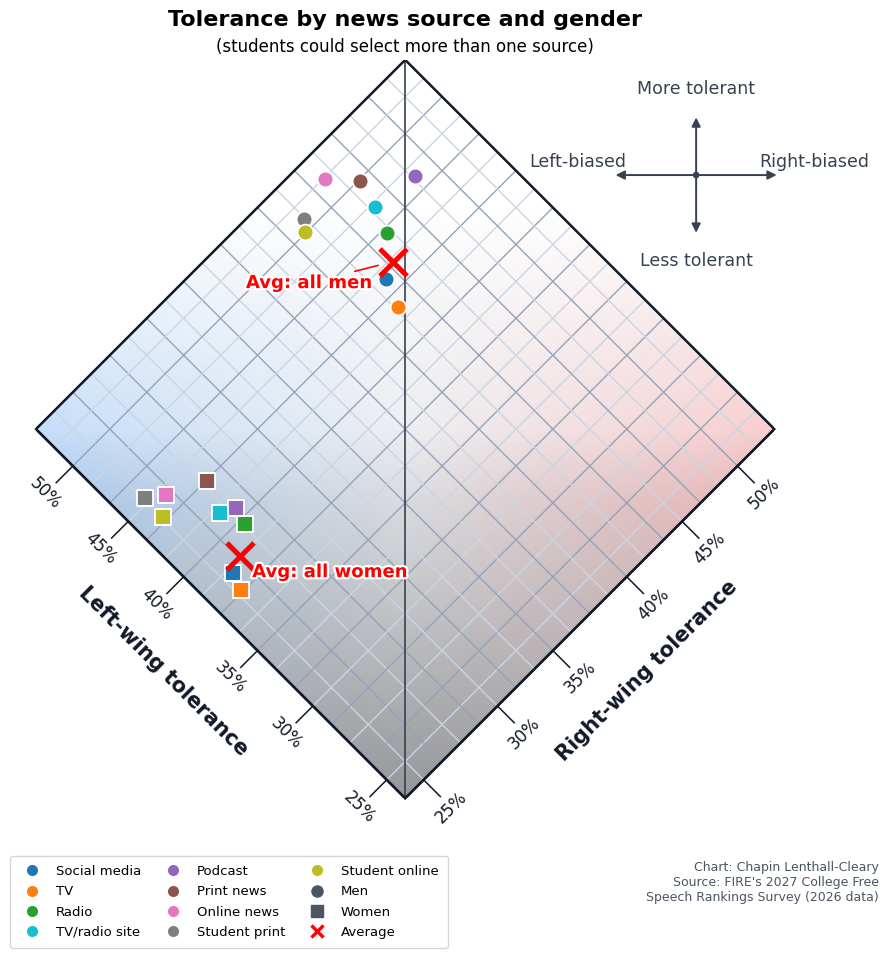

Saved: charts/news_source_gender_tolerance_diamond_2026.png
Diamond tick range: 23.0% to 52.6%

Point readout:
         point gender  left  right     n  avg tolerance
  Social media    Men  44.5   43.0 18761           43.8
  Social media  Women  38.9   25.1 33969           32.0
            TV    Men  43.0   42.4  8849           42.7
            TV  Women  37.9   24.7 17915           31.3
         Radio    Men  46.4   44.9  2572           45.7
         Radio  Women  40.4   27.5  5209           34.0
 TV/radio site    Men  47.9   45.4  2468           46.7
 TV/radio site  Women  41.8   27.0  4650           34.4
       Podcast    Men  47.6   48.3  4953           47.9
       Podcast  Women  41.4   27.8  8754           34.6
    Print news    Men  49.5   45.9  1263           47.7
    Print news  Women  43.6   27.8  1998           35.7
   Online news    Men  51.0   44.6  7431           47.8
   Online news  Women  44.7   25.5 15378           35.1
 Student print    Men  50.3   42.2  1564         

In [4]:
chart1_points = summarize_by_source(saw_news_question, include_none=SHOW_NONE)
plot_news_source_diamond(
    chart1_points,
    gender_averages(saw_news_question, "all"),
    OUT_DIR / "news_source_gender_tolerance_diamond_2026.png",
    title="Tolerance by news source and gender",
    subtitle="students could select more than one source",
)

## Chart 2: students who selected only one news source
Red X's mark the averages for one-source men and women and for all men and women. Be careful with the non-social-media points: radio, TV/radio site, print, student print, podcast, student online and (to a lesser degree) TV are small groups heavily affected by careless responding (for example, implausibly high acceptance of violence). `SINGLE_SOURCE_DROP` in the config cell removes groups from this chart.

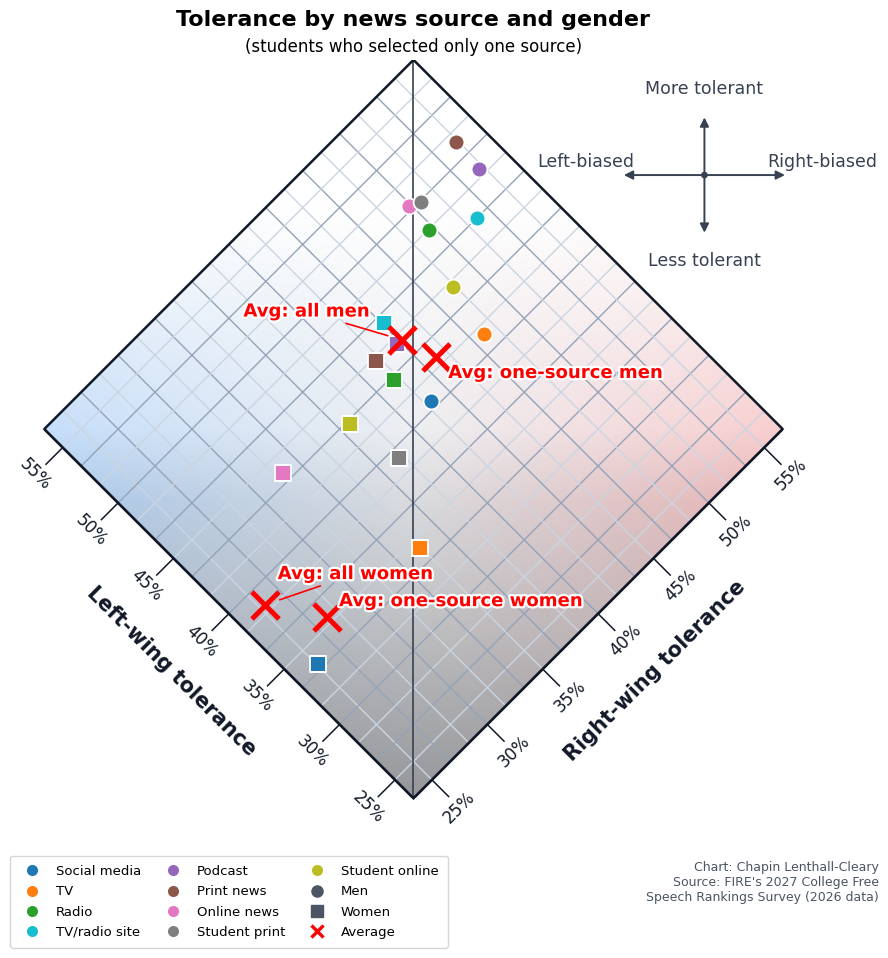

Saved: charts/news_source_gender_tolerance_diamond_single_source_only_2026.png
Diamond tick range: 24.0% to 57.0%

Point readout:
               point gender  left  right     n  avg tolerance
        Social media    Men  41.0   42.5  5658           41.8
        Social media  Women  34.3   25.8  7374           30.0
                  TV    Men  41.6   48.0   440           44.8
                  TV  Women  34.9   35.5   424           35.2
               Radio    Men  48.8   50.1   330           49.4
               Radio  Women  43.6   41.8   225           42.7
       TV/radio site    Men  47.1   52.8   250           50.0
       TV/radio site  Women  46.6   43.9   178           45.3
             Podcast    Men  49.2   55.1   260           52.2
             Podcast  Women  45.0   43.6   207           44.3
          Print news    Men  51.4   55.2   108           53.3
          Print news  Women  45.2   41.9    83           43.6
         Online news    Men  50.7   50.3   455           50.5
  

In [5]:
one_source = saw_news_question[saw_news_question["news_source_count"].eq(1)].copy()
plot_news_source_diamond(
    summarize_by_source(one_source, drop_sources=SINGLE_SOURCE_DROP),
    pd.concat([gender_averages(one_source, "one-source"), gender_averages(saw_news_question, "all")], ignore_index=True),
    OUT_DIR / "news_source_gender_tolerance_diamond_single_source_only_2026.png",
    title="Tolerance by news source and gender",
    subtitle="students who selected only one source",
)